(400000, 27)


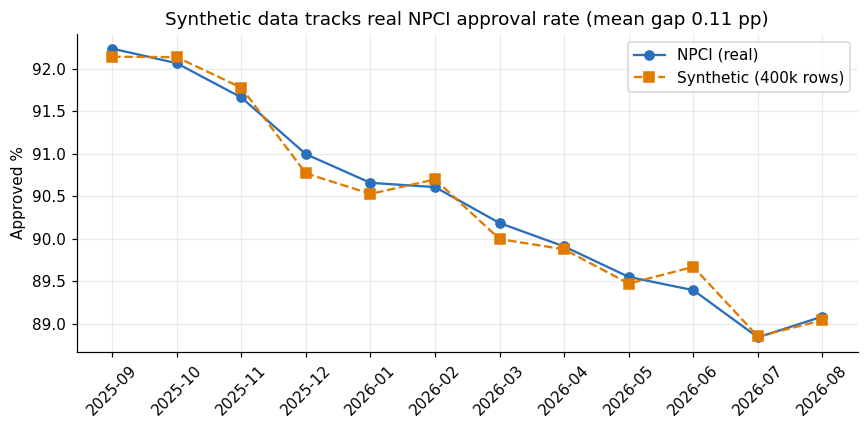

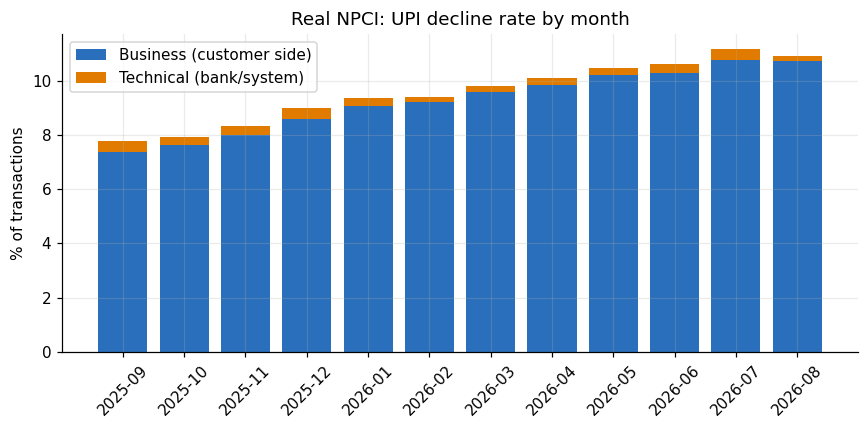

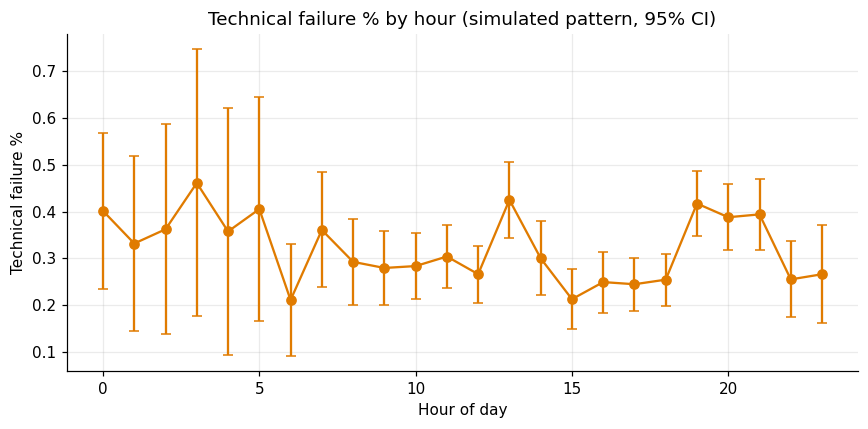

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from pathlib import Path
from scipy.stats import chi2_contingency

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
CLEAN, SYN, IMG = ROOT / "data" / "clean", ROOT / "data" / "synthetic", ROOT / "images"
IMG.mkdir(exist_ok=True)

tx = pd.read_csv(SYN / "upi_synthetic_txns.csv", low_memory=False)
tx["failure_type"] = tx.failure_type.fillna("")
tx["failed"] = (tx.status == "Failed").astype(int)
tx["technical"] = (tx.failure_type == "Technical").astype(int)
bank = pd.read_csv(CLEAN / "dim_bank.csv")
tx = tx.merge(bank, left_on="remitter_bank", right_on="bank_key", how="left")
tx["bank_type"] = tx.bank_type.fillna("Grouped small banks")
rem = pd.read_csv(CLEAN / "remitter_clean.csv")
print(tx.shape)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
BLUE, ORANGE = "#2a6fbb", "#e07b00"

# Chart 1: validation (real NPCI vs synthetic)
real = rem.groupby("month").apply(lambda g: (g.approved_pct * g.volume_mn).sum() / g.volume_mn.sum(), include_groups=False)
syn = tx.groupby("month").apply(lambda g: (g.status == "Success").mean() * 100, include_groups=False)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(real.index, real.values, marker="o", color=BLUE, label="NPCI (real)")
ax.plot(syn.index, syn.values, marker="s", ls="--", color=ORANGE, label="Synthetic (400k rows)")
ax.set_title("Synthetic data tracks real NPCI approval rate (mean gap 0.11 pp)")
ax.set_ylabel("Approved %"); ax.tick_params(axis="x", rotation=45); ax.legend()
fig.tight_layout(); fig.savefig(IMG / "01_validation.png"); plt.show()

# Chart 2: real NPCI decline rate by month (business vs technical)
m = rem.groupby("month").apply(lambda g: pd.Series({
    "Business decline %": (g.bd_pct * g.volume_mn).sum() / g.volume_mn.sum(),
    "Technical decline %": (g.td_pct * g.volume_mn).sum() / g.volume_mn.sum()}), include_groups=False)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(m.index, m["Business decline %"], color=BLUE, label="Business (customer side)")
ax.bar(m.index, m["Technical decline %"], bottom=m["Business decline %"], color=ORANGE, label="Technical (bank/system)")
ax.set_title("Real NPCI: UPI decline rate by month"); ax.set_ylabel("% of transactions")
ax.tick_params(axis="x", rotation=45); ax.legend()
fig.tight_layout(); fig.savefig(IMG / "02_decline_by_month.png"); plt.show()

# Chart 3: hourly technical failure with 95% CI (simulated pattern)
h = tx.groupby("hour").technical.agg(["mean", "count"])
se = np.sqrt(h["mean"] * (1 - h["mean"]) / h["count"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(h.index, h["mean"] * 100, yerr=1.96 * se * 100, fmt="o-", color=ORANGE, capsize=3)
ax.set_title("Technical failure % by hour (simulated pattern, 95% CI)")
ax.set_xlabel("Hour of day"); ax.set_ylabel("Technical failure %")
fig.tight_layout(); fig.savefig(IMG / "03_hourly_technical.png"); plt.show()

In [2]:
def risk_ratio(df, flag, outcome, label):
    """flag=1 group vs flag=0 group. Returns risk ratio, 95% CI, chi-square p-value."""
    a, b = df[df[flag] == 1][outcome], df[df[flag] == 0][outcome]
    p1, p0 = a.mean(), b.mean()
    rr = p1 / p0
    se = np.sqrt((1 - p1) / (p1 * len(a)) + (1 - p0) / (p0 * len(b)))     # standard error of log(RR)
    lo, hi = np.exp(np.log(rr) - 1.96 * se), np.exp(np.log(rr) + 1.96 * se)
    pval = chi2_contingency(pd.crosstab(df[flag], df[outcome]))[1]
    return {"comparison": label, "outcome": outcome, "rate_exposed_%": round(p1 * 100, 3), "rate_other_%": round(p0 * 100, 3),
            "risk_ratio": round(rr, 2), "ci_low": round(lo, 2), "ci_high": round(hi, 2), "p_value": "<0.001" if pval < 0.001 else round(pval, 3)}

tx["evening_peak"] = tx.hour.between(19, 21).astype(int)
tx["is_3g"] = (tx.network == "3G").astype(int)
tx["big_amount"] = (tx.amount >= 5000).astype(int)
tx["payments_bank"] = (tx.bank_type == "Payments bank").astype(int)

rows = [
    risk_ratio(tx, "is_month_end",  "failed",    "Month-end day vs other days"),
    risk_ratio(tx, "is_festival",   "technical", "Festival day vs normal day"),
    risk_ratio(tx, "evening_peak",  "technical", "7-10 pm vs rest of day"),
    risk_ratio(tx, "is_3g",         "technical", "3G network vs others"),
    risk_ratio(tx, "big_amount",    "failed",    "Amount Rs 5,000+ vs smaller"),
    risk_ratio(tx[tx.bank_type.isin(["Payments bank", "Private sector bank"])], "payments_bank", "failed", "Payments bank vs Private bank"),
]
rr_table = pd.DataFrame(rows)
rr_table.to_csv(ROOT / "data" / "risk_ratios.csv", index=False)
rr_table

,comparison,outcome,rate_exposed_%,rate_other_%,risk_ratio,ci_low,ci_high,p_value
0,Month-end day vs other days,failed,11.804,9.507,1.24,1.20,1.28,<0.001
1,Festival day vs normal day,technical,0.545,0.297,1.84,1.54,2.19,<0.001
2,7-10 pm vs rest of day,technical,0.401,0.287,1.39,1.23,1.58,<0.001
3,3G network vs others,technical,0.502,0.303,1.66,1.35,2.03,<0.001
4,"Amount Rs 5,000+ vs smaller",failed,14.833,9.434,1.57,1.52,1.63,<0.001
5,Payments bank vs Private bank,failed,19.962,6.744,2.96,2.86,3.07,<0.001


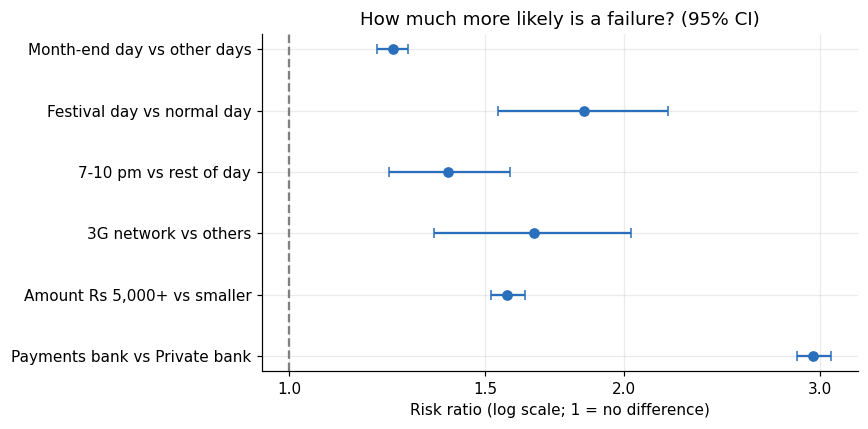

In [3]:
t = rr_table.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(t.risk_ratio, range(len(t)), xerr=[t.risk_ratio - t.ci_low, t.ci_high - t.risk_ratio], fmt="o", color=BLUE, capsize=3)
ax.axvline(1, color="grey", ls="--"); ax.set_yticks(range(len(t))); ax.set_yticklabels(t.comparison)
ax.set_xscale("log"); ax.set_xticks([1, 1.5, 2, 3]); ax.xaxis.set_major_formatter(ScalarFormatter()); ax.minorticks_off()
ax.set_xlabel("Risk ratio (log scale; 1 = no difference)")
ax.set_title("How much more likely is a failure? (95% CI)")
fig.tight_layout(); fig.savefig(IMG / "04_risk_ratios.png"); plt.show()